# Project 3: Avocado Price Predictor (Regression)

**Course:** Machine Learning, Chapter 14 Capstone Project

**Author:** Marzia Binte Iqbal

## Objective
Predict the **average price of an avocado** for a given week, region and type (conventional or organic). This is a **regression** problem because the target (`AveragePrice`) is a continuous number.

## Dataset
Hass Avocado Board weekly retail data (Kaggle "Avocado Prices"). This notebook expects these columns:

`Date, AveragePrice, Total Volume, 4046, 4225, 4770, Total Bags, Small Bags, Large Bags, XLarge Bags, type, region`

(an extra index column such as `Unnamed: 0` and a `year` column are ignored). Put the CSV in `/content/avocado.csv.csv` or change `DATA_PATH` below.

## Pipeline (matches the capstone guidelines)
| Step | Section |
|---|---|
| 1. Data acquisition & EDA | 1, 3 |
| 2. Preprocessing (cleaning, encoding, scaling) | 2, 5 |
| 3. Feature engineering (month, week, log volumes) | 2 |
| 4. Model selection: baseline + complex model | 5, 6 |
| 5. Hyperparameter tuning (RandomizedSearchCV) | 7 |
| 6. Rigorous evaluation (RMSE, MAE, R²) | 8 |

## Important design choice: split by time, not at random
Prices follow seasons and trends. If rows were split at random, the model would see weeks from the "future" while training, which is **data leakage** and gives overly optimistic results. So the **oldest 80% of the dates are used for training and the newest 20% for testing**, and tuning uses time-ordered cross-validation.


## 0. Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)


def save_fig(name):
    """Save the current figure to figures/ (handy for the PDF report)."""
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
# ---- Settings you can change ----
DATA_PATH = os.environ.get("DATA_PATH", "/content/avocado.csv")  # path to the CSV file
TRAIN_FRACTION = 0.8   # oldest 80% of the dates are used for training
N_ITER = 12            # number of random-search trials
CV_SPLITS = 3          # time-ordered cross-validation folds


## 1. Data acquisition

In [3]:
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)

df = df.rename(columns={
    "Total Volume": "TotalVolume", "4046": "PLU4046", "4225": "PLU4225", "4770": "PLU4770",
    "Total Bags": "TotalBags", "Small Bags": "SmallBags", "Large Bags": "LargeBags",
    "XLarge Bags": "XLargeBags",
})
required = ["Date", "AveragePrice", "TotalVolume", "PLU4046", "PLU4225", "PLU4770",
            "TotalBags", "SmallBags", "LargeBags", "XLargeBags", "type", "region"]
absent = [c for c in required if c not in df.columns]
if absent:
    raise ValueError(f"Missing columns {absent}. Columns found: {list(df.columns)}")
df = df[required].copy()

display(df.head())
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
display(df.describe().T)
print("\nTypes:", df["type"].unique(), "| number of regions:", df["region"].nunique())


Raw shape: (18249, 14)


,Date,AveragePrice,TotalVolume,PLU4046,PLU4225,PLU4770,TotalBags,SmallBags,LargeBags,XLargeBags,type,region
0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,Albany
1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,Albany
2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,Albany
3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,Albany
4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,Albany


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          18249 non-null  object 
 1   AveragePrice  18249 non-null  float64
 2   TotalVolume   18249 non-null  float64
 3   PLU4046       18249 non-null  float64
 4   PLU4225       18249 non-null  float64
 5   PLU4770       18249 non-null  float64
 6   TotalBags     18249 non-null  float64
 7   SmallBags     18249 non-null  float64
 8   LargeBags     18249 non-null  float64
 9   XLargeBags    18249 non-null  float64
 10  type          18249 non-null  object 
 11  region        18249 non-null  object 
dtypes: float64(9), object(3)
memory usage: 1.7+ MB

Missing values per column:
Date            0
AveragePrice    0
TotalVolume     0
PLU4046         0
PLU4225         0
PLU4770         0
TotalBags       0
SmallBags       0
LargeBags       0
XLargeBags      0
type            0
region     

,count,mean,std,min,25%,50%,75%,max
AveragePrice,18249.0,1.405978,4.026766e-01,0.44,1.10,1.37,1.66,3.25
TotalVolume,18249.0,850644.013009,3.453545e+06,84.56,10838.58,107376.76,432962.29,62505646.52
PLU4046,18249.0,293008.424531,1.264989e+06,0.00,854.07,8645.30,111020.20,22743616.17
PLU4225,18249.0,295154.568356,1.204120e+06,0.00,3008.78,29061.02,150206.86,20470572.61
PLU4770,18249.0,22839.735993,1.074641e+05,0.00,0.00,184.99,6243.42,2546439.11
TotalBags,18249.0,239639.202060,9.862424e+05,0.00,5088.64,39743.83,110783.37,19373134.37
SmallBags,18249.0,182194.686696,7.461785e+05,0.00,2849.42,26362.82,83337.67,13384586.80
LargeBags,18249.0,54338.088145,2.439660e+05,0.00,127.47,2647.71,22029.25,5719096.61
XLargeBags,18249.0,3106.426507,1.769289e+04,0.00,0.00,0.00,132.50,551693.65



Types: ['conventional' 'organic'] | number of regions: 54


## 2. Preprocessing & feature engineering

In [4]:
n_before = len(df)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna().drop_duplicates()
df = df[df["AveragePrice"] > 0]
print(f"Rows kept: {len(df):,} of {n_before:,}")

# --- Features from the date ---
df["year"] = df["Date"].dt.year
df["month"] = df["Date"].dt.month
df["weekofyear"] = df["Date"].dt.isocalendar().week.astype(int)

# --- Type as a 0/1 number ---
df["is_organic"] = (df["type"].str.lower() == "organic").astype(int)

# --- Volumes are very skewed, so use log(1 + x) ---
VOLUME_COLS = ["TotalVolume", "PLU4046", "PLU4225", "PLU4770", "TotalBags", "SmallBags", "LargeBags", "XLargeBags"]
for c in VOLUME_COLS:
    df["log_" + c] = np.log1p(df[c].clip(lower=0))

TARGET = "AveragePrice"
NUM_FEATURES = ["year", "month", "weekofyear", "is_organic"] + ["log_" + c for c in VOLUME_COLS]
CAT_FEATURES = ["region"]
FEATURES = NUM_FEATURES + CAT_FEATURES
print(f"{len(FEATURES)} features:", FEATURES)


Rows kept: 18,249 of 18,249
13 features: ['year', 'month', 'weekofyear', 'is_organic', 'log_TotalVolume', 'log_PLU4046', 'log_PLU4225', 'log_PLU4770', 'log_TotalBags', 'log_SmallBags', 'log_LargeBags', 'log_XLargeBags', 'region']


## 3. Exploratory data analysis (EDA)

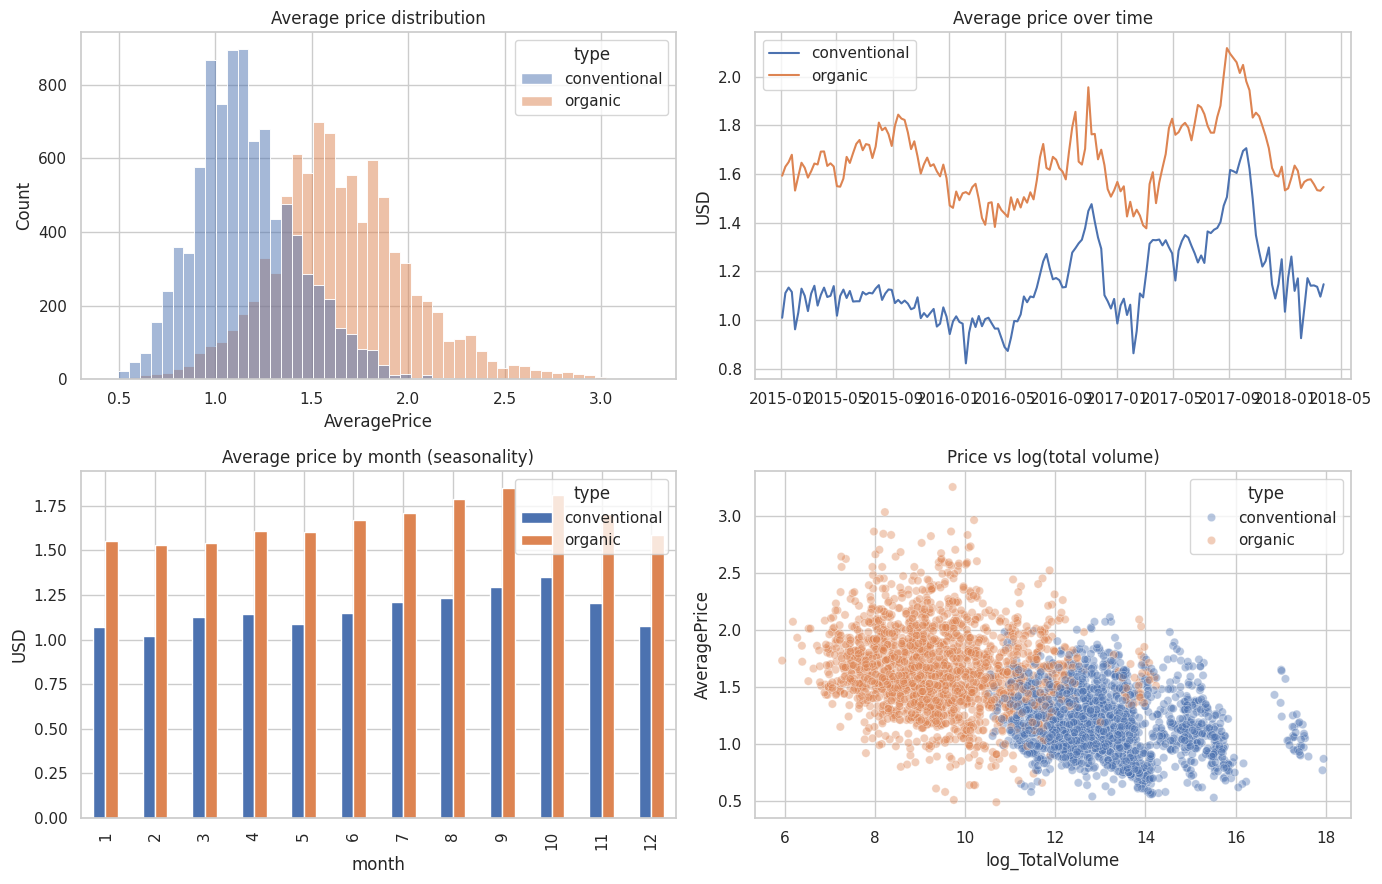

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(data=df, x=TARGET, hue="type", bins=50, ax=ax[0, 0])
ax[0, 0].set_title("Average price distribution")

for t, g in df.groupby("type"):
    series = g.groupby("Date")[TARGET].mean()
    ax[0, 1].plot(series.index, series.values, label=t)
ax[0, 1].set_title("Average price over time")
ax[0, 1].set_ylabel("USD")
ax[0, 1].legend()

df.groupby(["month", "type"])[TARGET].mean().unstack().plot(kind="bar", ax=ax[1, 0])
ax[1, 0].set_title("Average price by month (seasonality)")
ax[1, 0].set_ylabel("USD")

sns.scatterplot(data=df.sample(min(4000, len(df)), random_state=RANDOM_STATE),
                x="log_TotalVolume", y=TARGET, hue="type", alpha=0.4, ax=ax[1, 1])
ax[1, 1].set_title("Price vs log(total volume)")

save_fig("avocado_eda_overview")
plt.show()


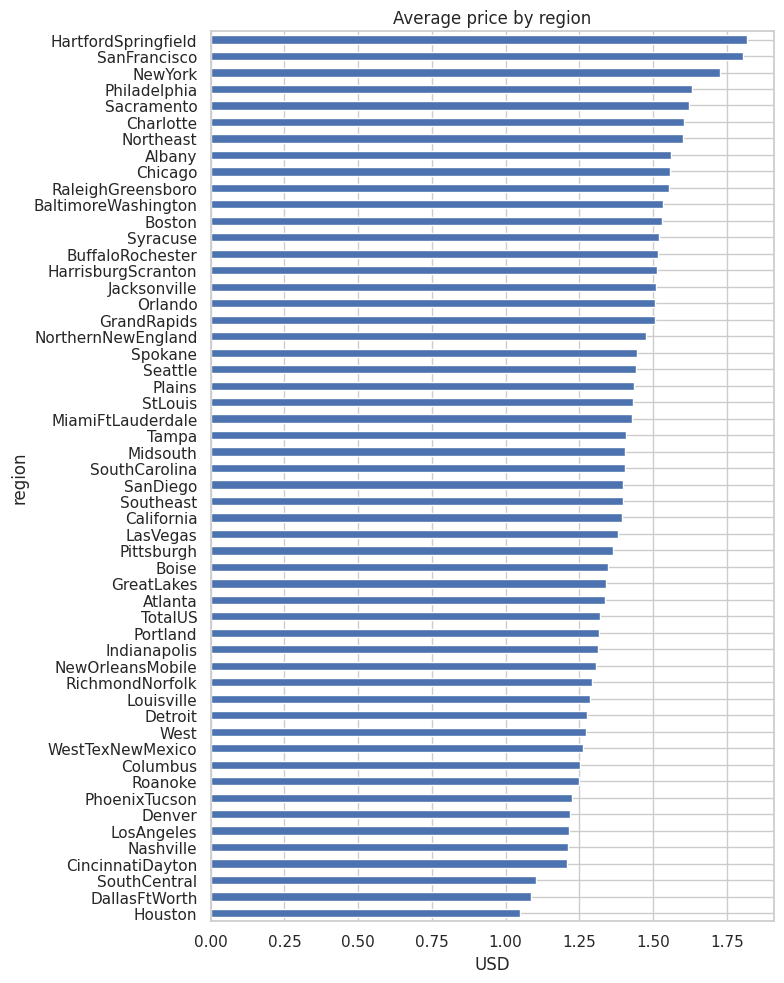

is_organic         0.616
month              0.162
weekofyear         0.146
year               0.093
log_XLargeBags    -0.380
log_PLU4225       -0.447
log_LargeBags     -0.479
log_SmallBags     -0.494
log_PLU4770       -0.507
log_PLU4046       -0.544
log_TotalBags     -0.575
log_TotalVolume   -0.583
Name: AveragePrice, dtype: float64


In [6]:
top_regions = df.groupby("region")[TARGET].mean().sort_values()
plt.figure(figsize=(8, 10))
top_regions.plot(kind="barh")
plt.title("Average price by region")
plt.xlabel("USD")
save_fig("avocado_price_by_region")
plt.show()

corr = df[NUM_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False)
print(corr.round(3))


### EDA insights
1. **Organic avocados cost more.** The conventional prices are centred around about $1.1, the organic prices around $1.6 to $1.8 (price distribution chart). `is_organic` has the strongest positive correlation with price (0.616) and it is also the most important feature of the Random Forest.

2. **The price level changes over time.** Conventional prices stay near $1.0 to $1.1 in 2015, then rise and reach about $1.7 in autumn 2017. Organic prices peak at about $2.1 in the same period. Because of this, the newest weeks (test set) have a higher mean price ($1.529) than the training weeks ($1.375). This is the reason why the split is done by time and not at random.

3. **There is a seasonal pattern, but treat it carefully.** The monthly averages are highest in September and October and lowest in the first months of the year. These averages mix different years, and the large 2017 price spike lies in the autumn months, so part of the "seasonality" is probably that one spike. The data ends in March 2018, so months 1 to 3 contain four years and the other months only three.

4. **Higher sales volume goes together with lower prices.** `log_TotalVolume` has the strongest negative correlation (-0.583). Part of this comes from the type: organic avocados sell in small volumes and cost more, conventional ones sell in large volumes and cost less. Correlation does not prove that volume causes the price.

5. **Prices differ by region.** HartfordSpringfield, SanFrancisco and NewYork have the highest average prices (about $1.7 to $1.8). Houston, DallasFtWorth and SouthCentral have the lowest (about $1.05 to $1.1). Note that some "regions" (for example TotalUS, West, Northeast) are larger areas that contain other regions, so the rows are not fully independent.

6. **Data quality is good, but volumes are very skewed.** There are 18,249 rows, 54 regions, 2 types, no missing values and no duplicate rows. TotalVolume has a mean of about 850,644 but a median of about 107,377 and a maximum of about 62.5 million, so the volumes were converted with log(1 + x).

## 4. Train / test split (by time)
The newest 20% of the dates become the test set. Nothing from the test period is used for training or tuning.

In [7]:
df = df.sort_values("Date").reset_index(drop=True)
dates = np.sort(df["Date"].unique())
cutoff = dates[int(len(dates) * TRAIN_FRACTION)]

train_df = df[df["Date"] < cutoff]
test_df = df[df["Date"] >= cutoff]
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

print(f"Train: {len(train_df):,} rows, {train_df['Date'].min().date()} to {train_df['Date'].max().date()}")
print(f"Test:  {len(test_df):,} rows, {test_df['Date'].min().date()} to {test_df['Date'].max().date()}")
print(f"Mean price  train {y_train.mean():.3f} | test {y_test.mean():.3f}")


Train: 14,577 rows, 2015-01-04 to 2017-07-30
Test:  3,672 rows, 2017-08-06 to 2018-03-25
Mean price  train 1.375 | test 1.529


## 5. Baselines
1. **Dummy**: always predicts the average training price (the minimum any model must beat).
2. **Linear Regression**: numeric features are scaled and `region` is one-hot encoded **inside a pipeline**, so the scaler and encoder learn only from training data.

In [8]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def evaluate(name, model):
    p_train, p_test = model.predict(X_train), model.predict(X_test)
    return {
        "Model": name,
        "Train RMSE": rmse(y_train, p_train),
        "Test RMSE": rmse(y_test, p_test),
        "Test MAE": mean_absolute_error(y_test, p_test),
        "Test R2": r2_score(y_test, p_test),
    }


def make_prep(scale):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num, NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ])


results = []

dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
results.append(evaluate("Dummy (mean price)", dummy))

linreg = Pipeline([("prep", make_prep(scale=True)), ("model", LinearRegression())]).fit(X_train, y_train)
results.append(evaluate("Linear Regression (baseline)", linreg))
display(pd.DataFrame(results).round(3))


,Model,Train RMSE,Test RMSE,Test MAE,Test R2
0,Dummy (mean price),0.399,0.423,0.322,-0.152
1,Linear Regression (baseline),0.195,0.290,0.217,0.460


## 6. Complex model: Random Forest
A Random Forest averages many decision trees and can learn non-linear patterns and interactions (for example "organic avocados in a certain region in autumn"). Trees do not need scaled features.

In [9]:
rf_default = Pipeline([
    ("prep", make_prep(scale=False)),
    ("model", RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)
results.append(evaluate("Random Forest (default)", rf_default))
display(pd.DataFrame(results).round(3))


,Model,Train RMSE,Test RMSE,Test MAE,Test R2
0,Dummy (mean price),0.399,0.423,0.322,-0.152
1,Linear Regression (baseline),0.195,0.290,0.217,0.460
2,Random Forest (default),0.042,0.279,0.209,0.498


## 7. Hyperparameter tuning (RandomizedSearchCV)
Cross-validation uses `TimeSeriesSplit`: each fold trains on earlier weeks and validates on later weeks. This needs the training data to be in date order, which it is.

In [10]:
rf_pipe = Pipeline([
    ("prep", make_prep(scale=False)),
    ("model", RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE)),
])

param_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [8, 12, 16, None],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": ["sqrt", 0.5, 1.0],
}

search = RandomizedSearchCV(
    rf_pipe, param_distributions=param_dist, n_iter=N_ITER,
    cv=TimeSeriesSplit(n_splits=CV_SPLITS),
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=1, verbose=1,
)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best cross-validated RMSE: {-search.best_score_:.3f}")

best_rf = search.best_estimator_            # refit on the full training set
results.append(evaluate("Random Forest (tuned)", best_rf))


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'model__n_estimators': 100, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': 12}
Best cross-validated RMSE: 0.265


## 8. Rigorous evaluation
- **RMSE**: typical error in USD (punishes big mistakes more)
- **MAE**: average absolute error in USD
- **R²**: share of the price variation explained (1.0 = perfect; below 0 = worse than the Dummy)

Compare **Train RMSE vs Test RMSE**: a much lower train error means overfitting.

,Model,Train RMSE,Test RMSE,Test MAE,Test R2
0,Dummy (mean price),0.399,0.423,0.322,-0.152
1,Linear Regression (baseline),0.195,0.290,0.217,0.460
2,Random Forest (default),0.042,0.279,0.209,0.498
3,Random Forest (tuned),0.114,0.288,0.213,0.467


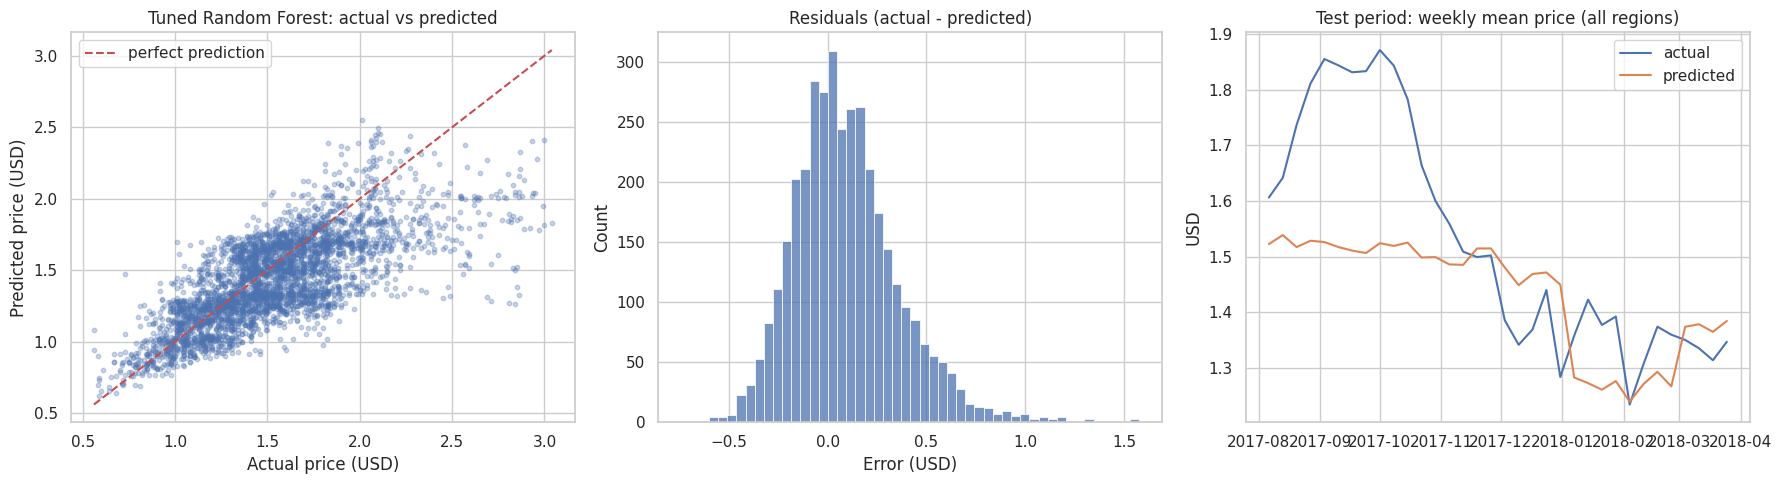

In [11]:
results_df = pd.DataFrame(results).round(3)
display(results_df)

pred = best_rf.predict(X_test)
resid = y_test.values - pred

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
idx = np.random.RandomState(RANDOM_STATE).choice(len(y_test), size=min(4000, len(y_test)), replace=False)
ax[0].scatter(y_test.values[idx], pred[idx], alpha=0.3, s=10)
lim = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, "r--", label="perfect prediction")
ax[0].set_xlabel("Actual price (USD)")
ax[0].set_ylabel("Predicted price (USD)")
ax[0].set_title("Tuned Random Forest: actual vs predicted")
ax[0].legend()

sns.histplot(resid, bins=50, ax=ax[1])
ax[1].set_title("Residuals (actual - predicted)")
ax[1].set_xlabel("Error (USD)")

weekly = pd.DataFrame({"Date": test_df["Date"].values, "actual": y_test.values, "predicted": pred}).groupby("Date").mean()
ax[2].plot(weekly.index, weekly["actual"], label="actual")
ax[2].plot(weekly.index, weekly["predicted"], label="predicted")
ax[2].legend()
ax[2].set_title("Test period: weekly mean price (all regions)")
ax[2].set_ylabel("USD")

save_fig("avocado_evaluation")
plt.show()


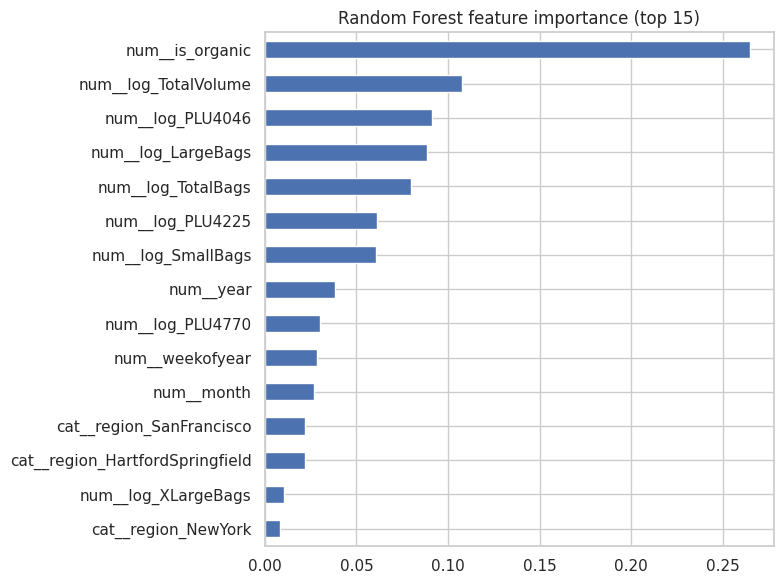

In [12]:
names = best_rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_rf.named_steps["model"].feature_importances_, index=names).sort_values().tail(15)
imp.plot(kind="barh", figsize=(8, 6), title="Random Forest feature importance (top 15)")
save_fig("avocado_feature_importance")
plt.show()


## 9. Demo: predict a price
This is the "live demo" slide of the presentation. It predicts the price for the most recent week in the test set and compares it with the real value.

In [13]:
def predict_price(row_df):
    """row_df: rows with the same columns as FEATURES."""
    return best_rf.predict(row_df[FEATURES])


last = test_df.iloc[[-1]]
print(f"Region: {last['region'].iloc[0]} | type: {last['type'].iloc[0]} | week: {last['Date'].iloc[0].date()}")
print(f"Actual price:    ${last[TARGET].iloc[0]:.2f}")
print(f"Predicted price: ${predict_price(last)[0]:.2f}")


Region: NewYork | type: conventional | week: 2018-03-25
Actual price:    $1.34
Predicted price: $1.60


## 10. Conclusion
**Which model won, and by how much?**
All three models beat the Dummy baseline (Test RMSE 0.423, R² -0.152; the negative R² happens because the test weeks have a higher mean price than the training weeks).


| Model | Test RMSE | Test MAE | Test R² |
|---|---|---|---|
| Dummy (mean price) | 0.423 | 0.322 | -0.152 |
| Linear Regression (baseline) | 0.290 | 0.217 | 0.460 |
| Random Forest (default) | 0.279 | 0.209 | 0.498 |
| Random Forest (tuned) | 0.288 | 0.213 | 0.467 |

The tuned Random Forest is the final model of the pipeline, because it had the best cross-validated RMSE on the training data (0.265). On the test set it reduces the Dummy error by about 32% and it is only slightly better than Linear Regression (0.288 vs 0.290). The untuned Random Forest scored a little better on the test set (0.279), but it was not chosen on the training data, and switching to it now would mean choosing a model by looking at the test set. The differences between the three real models are about 0.01 USD, and with one test period I cannot say that they are meaningful. A fair summary is: a Random Forest and a Linear Regression perform about the same on this problem.


**What does the error mean in practice?**
The tuned model is on average about $0.21 away from the true price (MAE), which is roughly 14% of the mean test price of $1.529. The typical error (RMSE) is about $0.29. The demo prediction was New York, conventional, 2018-03-25: predicted $1.60, actual $1.34 (an error of $0.26). This is one example only and not proof of quality. The model also underestimates the high-price weeks: in August to October 2017 the real weekly mean price was about $1.85 while the model predicted about $1.52 (see the last evaluation chart).


**Overfitting:** the default Random Forest has a train RMSE of 0.042 and a test RMSE of 0.279. Tuning (limited depth, larger leaves) made the gap between train and test error much smaller (train 0.114 vs test 0.288) but did not improve the test RMSE.


**Most important features:** `is_organic` (about 0.27 importance) and the volume features (`log_TotalVolume` about 0.11). Region and calendar features are less important. These are impurity-based importances, and the volume features are correlated with each other, so their importance is shared between them.


**Limitations:**
- The model uses the sales volumes of the same week as inputs. In real forecasting these numbers are not known in advance, so this is a model that estimates the price from market data, not a true forecast of future prices.
- The price level shifts over time (the test mean is higher than the train mean) and tree models cannot extrapolate outside the values seen in training (for example the year 2018).
- Only one time split was used, so the result depends on this one test period (August 2017 to March 2018), which includes an unusual price spike.
- There is no information about supply, weather, imports, holidays or costs, and the data are retail scanner data from 2015 to March 2018 only.
- Overlapping regions (TotalUS, West and so on) mean that rows are not independent.
- Only 12 random-search trials and a small parameter grid were used.

**Future work:** add weather, supply and holiday features; use lagged prices from previous weeks; test several time-based folds (rolling-origin evaluation); try gradient boosting (XGBoost / LightGBM); model each type or region separately; and serve the model with FastAPI.